# Elucidating the Design Space of Diffusion-Based Generative Models（EDM, 2022）

这个 notebook 使用八模态二维高斯混合分布，拆解 Karras et al. 提出的 EDM 设计：

1. 网络输入、输出和 skip connection 的预条件；
2. 对数正态噪声采样与加权去噪目标；
3. 去噪器、Score 和概率流 ODE 的关系；
4. 幂律噪声调度与参数 $\rho$；
5. Euler 与 Heun 二阶求解；
6. Stochastic Churn；
7. 学习去噪器与解析 Bayes 去噪器的独立对照。

> 运行环境：`conda activate pytorch`。随机种子固定为 42，可直接“全部运行”。

## 1. 八模态数据与 $\sigma_{\mathrm{data}}$

数据分布为

$$
p_{\mathrm{data}}(y)=\frac18\sum_{k=0}^{7}
\mathcal N\left(3(\cos\tfrac{k\pi}{4},\sin\tfrac{k\pi}{4}),0.25^2I\right).
$$

EDM 使用 $\sigma_{\mathrm{data}}$ 表示数据的典型标准差。这个分布的每坐标总体方差为

$$
\operatorname{Var}(y_j)=\frac{3^2}{2}+0.25^2=4.5625,
$$

所以 $\sigma_{\mathrm{data}}\approx2.136$，实验取 2.15。

In [1]:
from pathlib import Path
import math
import random
import time

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cpu":
    torch.set_num_threads(min(4, torch.get_num_threads()))

OUTPUT_DIR = Path("edm_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

DIM = 2
NUM_MODES = 8
RADIUS = 3.0
DATA_STD = 0.25
SIGMA_DATA = 2.15
TRAIN_STEPS = 6_000
BATCH_SIZE = 1_024
N_SAMPLES = 3_000

angles = torch.arange(NUM_MODES, device=DEVICE)*2*math.pi/NUM_MODES
CENTERS = RADIUS*torch.stack([torch.cos(angles), torch.sin(angles)], dim=1)
WEIGHTS = torch.full((NUM_MODES,), 1/NUM_MODES, device=DEVICE)

print(f"PyTorch: {torch.__version__}")
print(f"Device: {DEVICE}")
print(f"Theoretical per-coordinate std: {math.sqrt(RADIUS**2/2+DATA_STD**2):.4f}")
print(f"EDM sigma_data: {SIGMA_DATA}")
print(f"Output directory: {OUTPUT_DIR.resolve()}")

PyTorch: 2.5.1
Device: cuda
Theoretical per-coordinate std: 2.1360
EDM sigma_data: 2.15
Output directory: /home/zhangjinrui/my_program_code/Data_Processing/python/E2E/DLP/Diffuison/edm_outputs


In [2]:
def sample_data(n):
    labels = torch.multinomial(WEIGHTS, n, replacement=True)
    return CENTERS[labels]+DATA_STD*torch.randn(n, DIM, device=DEVICE)


with torch.no_grad():
    data_check = sample_data(20_000)
    assigned = torch.cdist(data_check, CENTERS).argmin(dim=1)
    empirical_weights = torch.bincount(assigned, minlength=NUM_MODES).float()/len(assigned)
print("Empirical mode weights:", empirical_weights.cpu().numpy().round(3))
print("Empirical coordinate std:", data_check.std(0).cpu().numpy().round(3))

Empirical mode weights: [0.122 0.124 0.126 0.127 0.128 0.127 0.123 0.123]
Empirical coordinate std: [2.135 2.136]


## 2. EDM 网络预条件

EDM 将原始网络 $F_\theta$ 包装成去噪器

$$
D_\theta(x;\sigma)=c_{\mathrm{skip}}(\sigma)x
+c_{\mathrm{out}}(\sigma)
F_\theta(c_{\mathrm{in}}(\sigma)x;c_{\mathrm{noise}}(\sigma)),
$$

其中

$$
c_{\mathrm{skip}}=\frac{\sigma_{\mathrm{data}}^2}{\sigma^2+\sigma_{\mathrm{data}}^2},\quad
c_{\mathrm{out}}=\frac{\sigma\sigma_{\mathrm{data}}}{\sqrt{\sigma^2+\sigma_{\mathrm{data}}^2}},
$$

$$
c_{\mathrm{in}}=\frac{1}{\sqrt{\sigma^2+\sigma_{\mathrm{data}}^2}},\quad
c_{\mathrm{noise}}=\frac14\log\sigma.
$$

小噪声时 skip connection 主导并接近恒等映射；大噪声时网络负责恢复数据结构。$c_{\mathrm{in}}$ 和 $c_{\mathrm{out}}$ 让网络内部的输入与目标尺度更加均衡。

In [3]:
class ResidualMLP(nn.Module):
    def __init__(self, hidden=128, time_dim=32):
        super().__init__()
        self.time_dim = time_dim
        self.net = nn.Sequential(
            nn.Linear(DIM+time_dim, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, DIM),
        )

    def forward(self, x, c_noise):
        frequencies = 2.0**torch.arange(self.time_dim//2, device=x.device, dtype=x.dtype)
        phase = c_noise[:, None]*frequencies[None, :]
        embedding = torch.cat([torch.sin(phase), torch.cos(phase)], dim=1)
        return self.net(torch.cat([x, embedding], dim=1))


class EDMDenoiser(nn.Module):
    def __init__(self, sigma_data=SIGMA_DATA):
        super().__init__()
        self.sigma_data = sigma_data
        self.net = ResidualMLP()

    def coefficients(self, sigma):
        sigma = sigma.reshape(-1)
        sigma_data = self.sigma_data
        denominator = sigma.square()+sigma_data**2
        c_skip = sigma_data**2/denominator
        c_out = sigma*sigma_data/torch.sqrt(denominator)
        c_in = torch.rsqrt(denominator)
        c_noise = torch.log(sigma.clamp_min(1e-12))/4
        return c_skip, c_out, c_in, c_noise

    def forward(self, x, sigma):
        sigma = torch.as_tensor(sigma, device=x.device, dtype=x.dtype).reshape(-1)
        if sigma.numel() == 1:
            sigma = sigma.expand(len(x))
        c_skip, c_out, c_in, c_noise = self.coefficients(sigma)
        residual = self.net(c_in[:, None]*x, c_noise)
        return c_skip[:, None]*x+c_out[:, None]*residual


model = EDMDenoiser().to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
print(model)
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters()):,}")

EDMDenoiser(
  (net): ResidualMLP(
    (net): Sequential(
      (0): Linear(in_features=34, out_features=128, bias=True)
      (1): SiLU()
      (2): Linear(in_features=128, out_features=128, bias=True)
      (3): SiLU()
      (4): Linear(in_features=128, out_features=128, bias=True)
      (5): SiLU()
      (6): Linear(in_features=128, out_features=2, bias=True)
    )
  )
)
Trainable parameters: 37,762


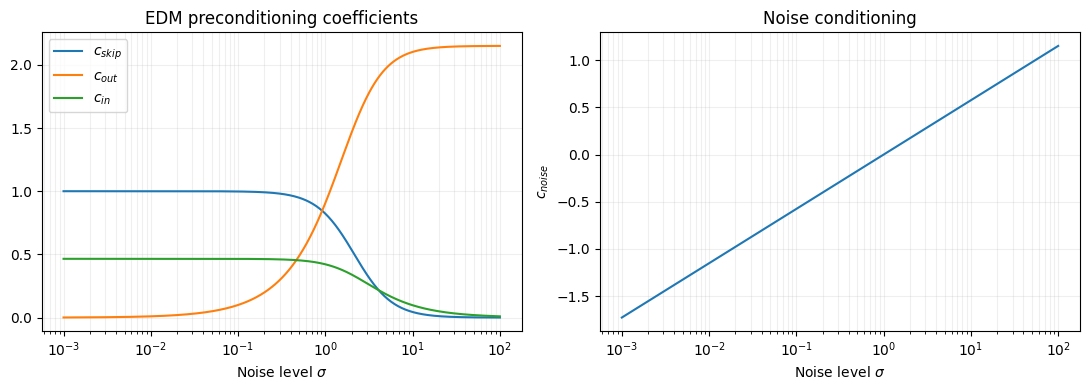

In [4]:
sigma_grid = torch.logspace(-3, 2, 500, device=DEVICE)
c_skip, c_out, c_in, c_noise = model.coefficients(sigma_grid)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].semilogx(sigma_grid.cpu(), c_skip.cpu(), label=r"$c_{skip}$")
axes[0].semilogx(sigma_grid.cpu(), c_out.cpu(), label=r"$c_{out}$")
axes[0].semilogx(sigma_grid.cpu(), c_in.cpu(), label=r"$c_{in}$")
axes[0].set(xlabel=r"Noise level $\sigma$", title="EDM preconditioning coefficients")
axes[0].legend()
axes[0].grid(alpha=0.2, which="both")
axes[1].semilogx(sigma_grid.cpu(), c_noise.cpu())
axes[1].set(xlabel=r"Noise level $\sigma$", ylabel=r"$c_{noise}$", title="Noise conditioning")
axes[1].grid(alpha=0.2, which="both")
fig.tight_layout()
fig.savefig(OUTPUT_DIR/"01_preconditioning.png", dpi=160, bbox_inches="tight")
plt.show()

## 3. 对数正态噪声与加权去噪目标

训练时采样

$$
\log\sigma\sim\mathcal N(P_{\mathrm{mean}},P_{\mathrm{std}}^2),
\qquad P_{\mathrm{mean}}=-1.2,\ P_{\mathrm{std}}=1.2,
$$

并构造 $x=y+\sigma\epsilon$。损失为

$$
\mathbb E\left[
\lambda(\sigma)\|D_\theta(y+\sigma\epsilon;\sigma)-y\|^2
\right],
$$

$$
\lambda(\sigma)=
\frac{\sigma^2+\sigma_{\mathrm{data}}^2}
{(\sigma\sigma_{\mathrm{data}})^2}.
$$

结合预条件后，不同噪声水平对应的网络训练目标具有较均衡的有效尺度。

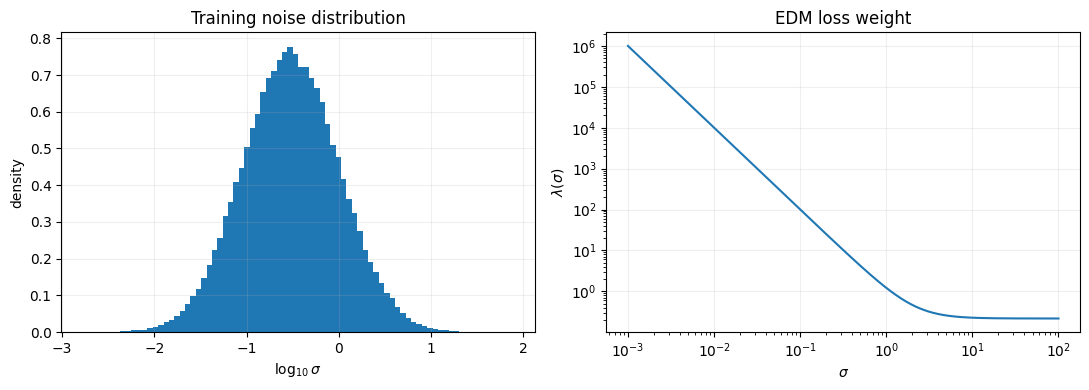

In [5]:
P_MEAN, P_STD = -1.2, 1.2


def edm_loss(model, clean):
    sigma = torch.exp(P_MEAN+P_STD*torch.randn(len(clean), device=DEVICE))
    noisy = clean+sigma[:, None]*torch.randn_like(clean)
    denoised = model(noisy, sigma)
    weight = (sigma.square()+model.sigma_data**2)/(sigma*model.sigma_data).square()
    return (weight[:, None]*(denoised-clean).square()).mean()


sampled_sigmas = torch.exp(P_MEAN+P_STD*torch.randn(100_000))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(torch.log10(sampled_sigmas).numpy(), bins=80, density=True)
axes[0].set(xlabel=r"$\log_{10}\sigma$", ylabel="density", title="Training noise distribution")
weight_grid = (sigma_grid.square()+SIGMA_DATA**2)/(sigma_grid*SIGMA_DATA).square()
axes[1].loglog(sigma_grid.cpu(), weight_grid.cpu())
axes[1].set(xlabel=r"$\sigma$", ylabel=r"$\lambda(\sigma)$", title="EDM loss weight")
for ax in axes:
    ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(OUTPUT_DIR/"02_training_noise_and_weight.png", dpi=160, bbox_inches="tight")
plt.show()

In [6]:
losses = []
model.train()
training_started = time.perf_counter()
for step in range(1, TRAIN_STEPS+1):
    loss = edm_loss(model, sample_data(BATCH_SIZE))
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()
    losses.append(loss.item())

    if step == 1 or step % 600 == 0:
        print(f"step {step:4d}/{TRAIN_STEPS} | loss(200-step avg)={np.mean(losses[-200:]):.6f}")

print(f"Training finished in {time.perf_counter()-training_started:.1f} s")
torch.save(model.state_dict(), OUTPUT_DIR/"edm_denoiser_state_dict.pt")

step    1/6000 | loss(200-step avg)=1.030949


step  600/6000 | loss(200-step avg)=0.999145


step 1200/6000 | loss(200-step avg)=0.998284


step 1800/6000 | loss(200-step avg)=0.995922


step 2400/6000 | loss(200-step avg)=0.999626


...

step 3600/6000 | loss(200-step avg)=0.691966


step 4200/6000 | loss(200-step avg)=0.687058


step 4800/6000 | loss(200-step avg)=0.690111


step 5400/6000 | loss(200-step avg)=0.687630


step 6000/6000 | loss(200-step avg)=0.684733
Training finished in 16.8 s


## 4. 解析 Bayes 去噪器与 Score

对加性高斯噪声 $x=y+\sigma\epsilon$，平方误差的最优去噪器是后验均值：

$$
D^*(x;\sigma)=\mathbb E[y\mid x].
$$

高斯混合分布的责任概率与分量后验均值均可解析计算。Tweedie 公式进一步给出

$$
\nabla_x\log p(x;\sigma)=\frac{D^*(x;\sigma)-x}{\sigma^2}.
$$

因此 EDM 去噪器隐式地定义了每个噪声水平的 Score。

    sigma     denoiser MSE
    0.020        0.0000014
    0.050        0.0000070
    0.100        0.0000443
    0.300        0.0008491
    1.000        0.0050359
    3.000        0.0180872
   10.000        0.0461746


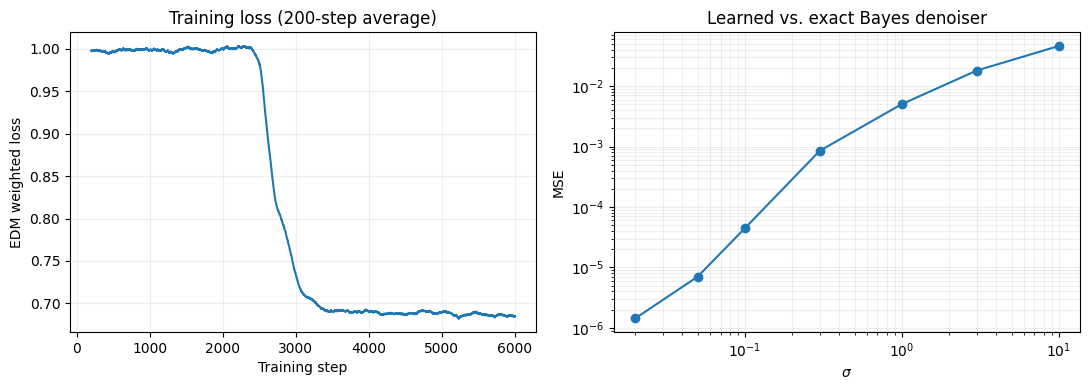

In [7]:
def exact_denoiser(x, sigma):
    sigma = torch.as_tensor(sigma, device=x.device, dtype=x.dtype).reshape(-1)
    if sigma.numel() == 1:
        sigma = sigma.expand(len(x))
    noise_var = sigma.square()
    marginal_var = DATA_STD**2+noise_var
    delta = x[:, None, :]-CENTERS[None, :, :]
    logits = torch.log(WEIGHTS)[None, :]-delta.square().sum(-1)/(2*marginal_var[:, None])
    responsibilities = torch.softmax(logits, dim=1)
    component_posterior_mean = (
        noise_var[:, None, None]*CENTERS[None, :, :]
        +DATA_STD**2*x[:, None, :]
    )/marginal_var[:, None, None]
    return (responsibilities[:, :, None]*component_posterior_mean).sum(dim=1)


@torch.no_grad()
def evaluate_denoiser(n=10_000):
    rows = []
    for sigma_value in [0.02, 0.05, 0.1, 0.3, 1.0, 3.0, 10.0]:
        sigma = torch.full((n,), sigma_value, device=DEVICE)
        noisy = sample_data(n)+sigma[:, None]*torch.randn(n, DIM, device=DEVICE)
        pred = model(noisy, sigma)
        target = exact_denoiser(noisy, sigma)
        mse = (pred-target).square().mean().item()
        rows.append((sigma_value, mse))
    return np.asarray(rows)


denoiser_metrics = evaluate_denoiser()
print(f"{'sigma':>9} {'denoiser MSE':>16}")
for sigma_value, mse in denoiser_metrics:
    print(f"{sigma_value:9.3f} {mse:16.7f}")

window = 200
loss_smooth = np.convolve(losses, np.ones(window)/window, mode="valid")
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(np.arange(window, len(losses)+1), loss_smooth)
axes[0].set(xlabel="Training step", ylabel="EDM weighted loss", title=f"Training loss ({window}-step average)")
axes[1].loglog(denoiser_metrics[:, 0], denoiser_metrics[:, 1], "o-")
axes[1].set(xlabel=r"$\sigma$", ylabel="MSE", title="Learned vs. exact Bayes denoiser")
for ax in axes:
    ax.grid(alpha=0.2, which="both")
fig.tight_layout()
fig.savefig(OUTPUT_DIR/"03_training_and_denoiser_error.png", dpi=160, bbox_inches="tight")
plt.show()

## 5. EDM 幂律噪声调度

采样使用

$$
\sigma_i=\left[
\sigma_{\max}^{1/\rho}
+\frac{i}{N-1}
\left(\sigma_{\min}^{1/\rho}-\sigma_{\max}^{1/\rho}\right)
\right]^\rho.
$$

$\rho=7$ 会把更多步骤分配给低噪声区域，因为生成细节在该区域变化更快。序列末尾额外连接 $\sigma_N=0$，最后一步输出干净样本。

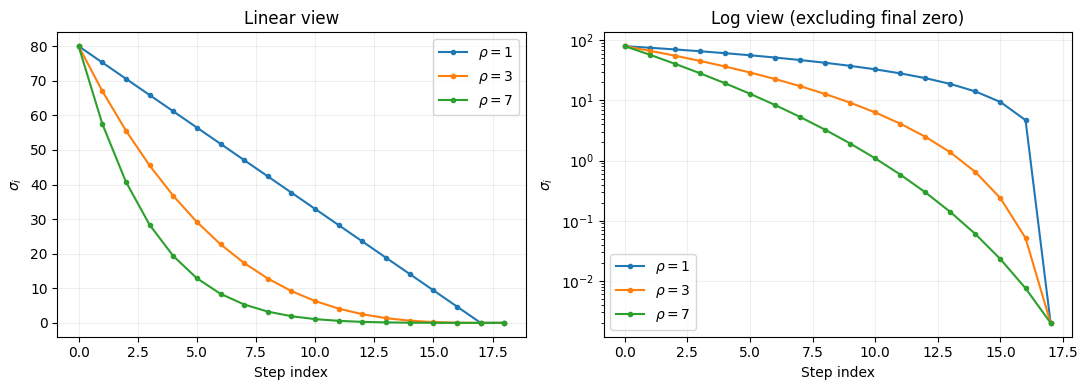

In [8]:
def noise_schedule(n, sigma_min=0.002, sigma_max=80.0, rho=7.0):
    if n < 2:
        raise ValueError("n must be at least 2")
    ramp = torch.linspace(0, 1, n, device=DEVICE, dtype=torch.float64)
    sigmas = (
        sigma_max**(1/rho)
        +ramp*(sigma_min**(1/rho)-sigma_max**(1/rho))
    )**rho
    return torch.cat([sigmas, sigmas.new_zeros(1)])


fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for rho in [1, 3, 7]:
    schedule = noise_schedule(18, rho=rho).cpu().numpy()
    axes[0].plot(schedule, "o-", ms=3, label=rf"$\rho={rho}$")
    axes[1].semilogy(schedule[:-1], "o-", ms=3, label=rf"$\rho={rho}$")
axes[0].set(xlabel="Step index", ylabel=r"$\sigma_i$", title="Linear view")
axes[1].set(xlabel="Step index", ylabel=r"$\sigma_i$", title="Log view (excluding final zero)")
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(OUTPUT_DIR/"04_noise_schedules.png", dpi=160, bbox_inches="tight")
plt.show()

## 6. Probability Flow ODE、Euler 与 Heun

以噪声标准差 $\sigma$ 作为时间变量时，EDM 的 ODE 为

$$
\frac{dx}{d\sigma}=\frac{x-D_\theta(x;\sigma)}{\sigma}.
$$

Euler 每步只在起点计算一次导数。Heun 先做 Euler 预测，再在终点计算第二次导数并取平均，因此除最终到零的一步外每步需要两次去噪器调用。18 个噪声点对应 Euler 18 NFE、Heun 35 NFE。

Churn 在选定噪声区间先临时增大 $\sigma$ 并注入噪声，再执行 ODE 步骤。它可以纠正部分采样误差，但过强会破坏结构。

In [9]:
@torch.no_grad()
def edm_sample(denoiser, initial_noise, steps=18, method="heun", churn=0.0,
               sigma_min=0.002, sigma_max=80.0, rho=7.0,
               churn_min=0.0, churn_max=float("inf"), seed=123,
               keep_stages=False):
    if method not in {"euler", "heun"}:
        raise ValueError("method must be 'euler' or 'heun'")
    sigmas = noise_schedule(steps, sigma_min, sigma_max, rho)
    generator = torch.Generator(device=DEVICE).manual_seed(seed)
    x = initial_noise.double()*sigmas[0]
    snapshots = {0: x.float().cpu().numpy().copy()}
    nfe = 0

    for i in range(steps):
        sigma, sigma_next = sigmas[i], sigmas[i+1]
        use_churn = churn_min <= sigma <= churn_max
        gamma = min(churn/steps, math.sqrt(2)-1) if churn > 0 and use_churn else 0.0
        sigma_hat = sigma*(1+gamma)
        if gamma > 0:
            noise = torch.randn(len(x), DIM, device=DEVICE, dtype=torch.float64, generator=generator)
            x = x+torch.sqrt((sigma_hat.square()-sigma.square()).clamp_min(0))*noise

        denoised = denoiser(x.float(), sigma_hat.float()).double()
        nfe += 1
        derivative = (x-denoised)/sigma_hat
        step_size = sigma_next-sigma_hat
        x_euler = x+step_size*derivative

        if method == "heun" and sigma_next > 0:
            denoised_next = denoiser(x_euler.float(), sigma_next.float()).double()
            nfe += 1
            derivative_next = (x_euler-denoised_next)/sigma_next
            x = x+step_size*(derivative+derivative_next)/2
        else:
            x = x_euler

        if keep_stages and i+1 in {steps//4, steps//2, 3*steps//4, steps}:
            snapshots[i+1] = x.float().cpu().numpy().copy()
    return x.float().cpu().numpy(), snapshots, nfe


initial_noise = torch.randn(N_SAMPLES, DIM, device=DEVICE, generator=torch.Generator(device=DEVICE).manual_seed(123))
sampling_started = time.perf_counter()
euler18, _, euler_nfe = edm_sample(model, initial_noise, steps=18, method="euler")
heun18, heun_stages, heun_nfe = edm_sample(model, initial_noise, steps=18, method="heun", keep_stages=True)
churn18, _, churn_nfe = edm_sample(model, initial_noise, steps=18, method="heun", churn=4.0)
oracle18, _, oracle_nfe = edm_sample(exact_denoiser, initial_noise, steps=18, method="heun")
print(f"Four samplers finished in {time.perf_counter()-sampling_started:.1f} s")
print(f"Euler NFE={euler_nfe}, Heun NFE={heun_nfe}, Heun+churn NFE={churn_nfe}")

Four samplers finished in 0.1 s
Euler NFE=18, Heun NFE=35, Heun+churn NFE=35


## 7. 求解器、Churn 与 Oracle 对照

所有采样器使用相同的初始高斯噪声。Oracle Heun 将学习去噪器替换为解析 Bayes 去噪器，用于衡量噪声调度与有限步 ODE 求解本身的误差。

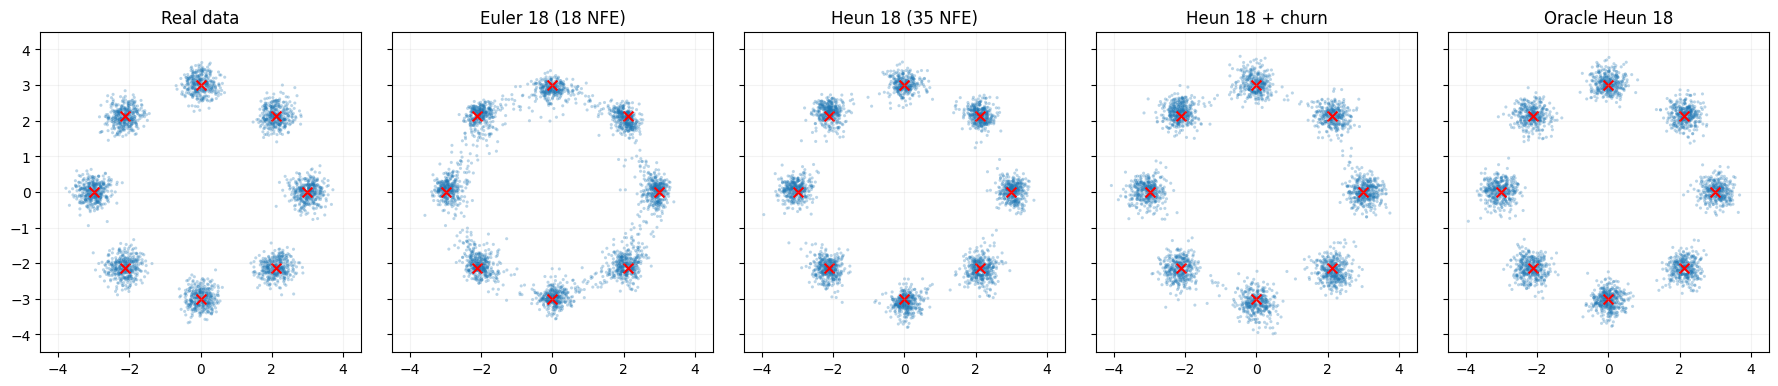

sampler                   modes    max |w-1/8|   center err   avg std
Real data                     8         0.0067       0.0138    0.2512
Euler 18 (18 NFE)             8         0.0163       0.1197    0.2709
Heun 18 (35 NFE)              8         0.0183       0.0622    0.2318
Heun 18 + churn               8         0.0123       0.0710    0.2689
Oracle Heun 18                8         0.0143       0.0435    0.2507


In [10]:
def scatter(ax, points, title):
    ax.scatter(points[:, 0], points[:, 1], s=5, alpha=0.3, edgecolors="none")
    ax.scatter(CENTERS[:, 0].cpu(), CENTERS[:, 1].cpu(), c="red", marker="x", s=50)
    ax.set(title=title, xlim=(-4.5, 4.5), ylim=(-4.5, 4.5))
    ax.set_aspect("equal")
    ax.grid(alpha=0.15)


with torch.no_grad():
    real = sample_data(N_SAMPLES).cpu().numpy()

comparison = [
    ("Real data", real),
    (f"Euler 18 ({euler_nfe} NFE)", euler18),
    (f"Heun 18 ({heun_nfe} NFE)", heun18),
    ("Heun 18 + churn", churn18),
    ("Oracle Heun 18", oracle18),
]
fig, axes = plt.subplots(1, 5, figsize=(18, 3.6), sharex=True, sharey=True)
for ax, (title, points) in zip(axes, comparison):
    scatter(ax, points, title)
fig.tight_layout()
fig.savefig(OUTPUT_DIR/"05_solver_comparison.png", dpi=160, bbox_inches="tight")
plt.show()


def mode_metrics(points):
    points_t = torch.as_tensor(points, dtype=torch.float32, device=DEVICE)
    labels = torch.cdist(points_t, CENTERS).argmin(dim=1)
    weights = torch.bincount(labels, minlength=NUM_MODES).float()/len(points_t)
    means = torch.stack([points_t[labels == i].mean(0) for i in range(NUM_MODES)])
    stds = torch.stack([points_t[labels == i].std(0) for i in range(NUM_MODES)])
    modes = int((weights > 0.02).sum())
    max_weight_error = (weights-1/NUM_MODES).abs().max().item()
    center_error = torch.linalg.vector_norm(means-CENTERS, dim=1).mean().item()
    return modes, max_weight_error, center_error, stds.mean().item()


print(f"{'sampler':<24} {'modes':>6} {'max |w-1/8|':>14} {'center err':>12} {'avg std':>9}")
for title, points in comparison:
    modes, weight_error, center_error, avg_std = mode_metrics(points)
    print(f"{title:<24} {modes:6d} {weight_error:14.4f} {center_error:12.4f} {avg_std:9.4f}")

## 8. Heun 步数与 NFE

Heun 的步数增加会降低截断误差，但网络调用数约为 $2N-1$。比较 8、12、18、32 个噪声点，观察质量与计算量的折衷。

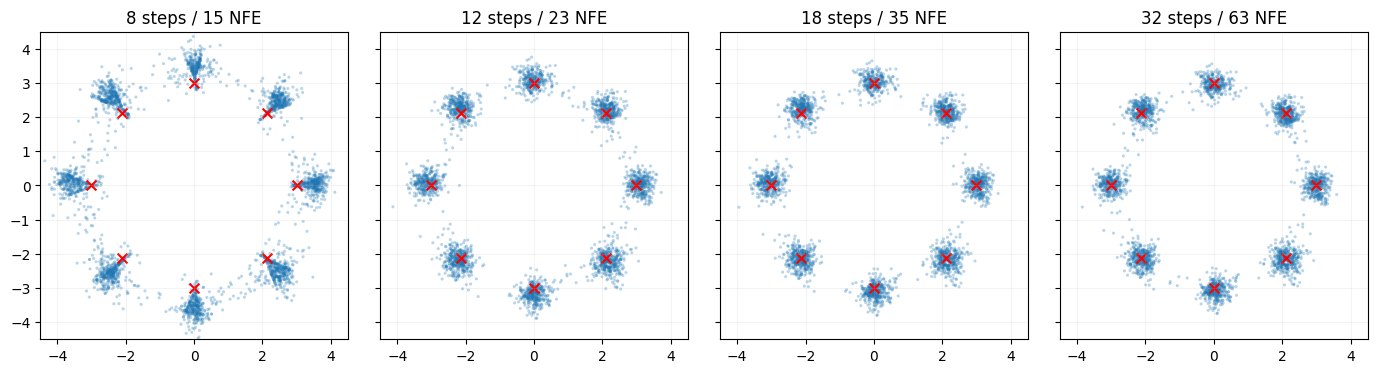

  steps    NFE  modes    max |w-1/8|   center err   avg std
      8     15      8         0.0190       0.4874    0.2960
     12     23      8         0.0133       0.1146    0.2463
     18     35      8         0.0183       0.0622    0.2318
     32     63      8         0.0153       0.0446    0.2330


In [11]:
step_values = [8, 12, 18, 32]
step_samples, step_nfes = {}, {}
for steps in step_values:
    step_samples[steps], _, step_nfes[steps] = edm_sample(model, initial_noise, steps=steps, method="heun")

fig, axes = plt.subplots(1, 4, figsize=(14, 3.5), sharex=True, sharey=True)
for ax, steps in zip(axes, step_values):
    scatter(ax, step_samples[steps], f"{steps} steps / {step_nfes[steps]} NFE")
fig.tight_layout()
fig.savefig(OUTPUT_DIR/"06_heun_steps.png", dpi=160, bbox_inches="tight")
plt.show()

print(f"{'steps':>7} {'NFE':>6} {'modes':>6} {'max |w-1/8|':>14} {'center err':>12} {'avg std':>9}")
for steps in step_values:
    modes, weight_error, center_error, avg_std = mode_metrics(step_samples[steps])
    print(f"{steps:7d} {step_nfes[steps]:6d} {modes:6d} {weight_error:14.4f} {center_error:12.4f} {avg_std:9.4f}")

## 9. Heun 反向轨迹

初始状态的标准差约为 $\sigma_{\max}=80$，远大于数据尺度。随着 $\sigma$ 下降，样本先被拉回有限范围，再形成圆环，最后收缩成八个窄模态。

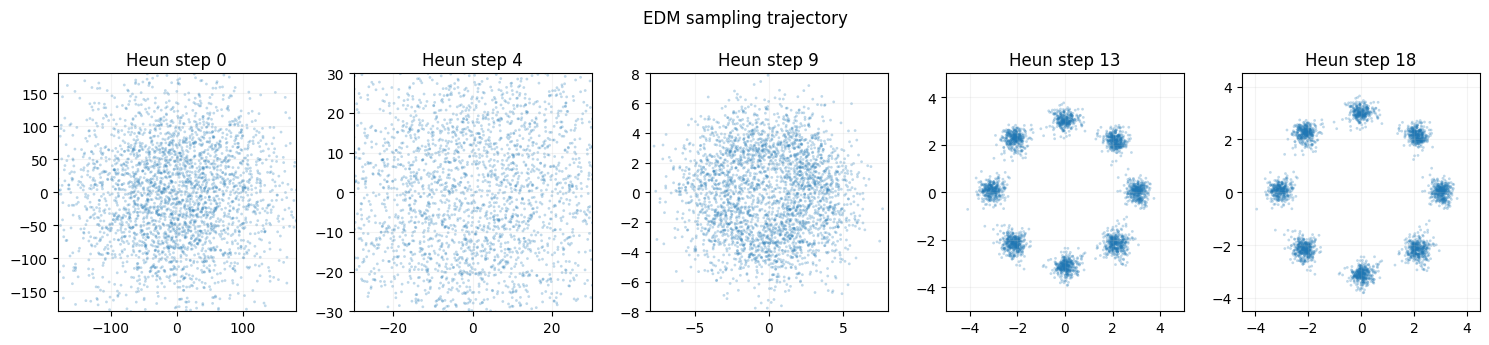

In [12]:
stage_ids = [0, 18//4, 18//2, 3*18//4, 18]
fig, axes = plt.subplots(1, 5, figsize=(15, 3.1))
view_limits = [180, 30, 8, 5, 4.5]
for ax, stage, limit in zip(axes, stage_ids, view_limits):
    points = heun_stages[stage]
    ax.scatter(points[:, 0], points[:, 1], s=4, alpha=0.28, edgecolors="none")
    ax.set_title(f"Heun step {stage}")
    ax.set_xlim(-limit, limit)
    ax.set_ylim(-limit, limit)
    ax.set_aspect("equal")
    ax.grid(alpha=0.15)
fig.suptitle("EDM sampling trajectory", y=1.04)
fig.tight_layout()
fig.savefig(OUTPUT_DIR/"07_heun_trajectory.png", dpi=160, bbox_inches="tight")
plt.show()

## 10. 代码与论文设计对应关系

| Notebook 对象 | EDM 设计 | 作用 |
|---|---|---|
| `EDMDenoiser.coefficients()` | $c_{skip},c_{out},c_{in},c_{noise}$ | 平衡不同噪声尺度的网络输入输出 |
| `edm_loss()` | 对数正态 $p_{train}(\sigma)$ 与 $\lambda(\sigma)$ | 加权多尺度去噪训练 |
| `exact_denoiser()` | $\mathbb E[y\mid x]$ | 解析 Bayes 基准与隐式 Score |
| `noise_schedule()` | $\rho$ 幂律调度 | 将步骤分配到变化较快的低噪声区 |
| `edm_sample(..., "euler")` | Algorithm 2 一阶更新 | 每步一次 NFE |
| `edm_sample(..., "heun")` | 二阶校正 | 除末步外每步两次 NFE |
| `churn` | $S_{churn}$ | 临时增加噪声，纠正采样误差 |

实验是否成功需要同时检查：去噪器是否接近解析后验均值、Oracle 求解是否正确、八个模态是否全部覆盖、分量中心与标准差是否接近目标，以及增加 Heun 步数后误差是否趋于稳定。